# Audio EDA — Frequency Analysis & Denoising

Explores the frequency content of the anonymized audio files using FFT and Welch's PSD,
then designs high/low-pass filters based on the observed spectrum.

In [1]:
import numpy as np
import scipy.io.wavfile as wav
import scipy.signal as signal
import matplotlib.pyplot as plt
from pathlib import Path

AUDIO_DIR = Path("anonymized_audios")
audio_files = sorted(AUDIO_DIR.glob("*.wav"))
print(f"Found {len(audio_files)} audio files")

# Inspect one file
sr, data = wav.read(audio_files[0])
# Stereo -> mono by averaging channels
if data.ndim == 2:
    data = data.mean(axis=1)
print(f"Sample rate : {sr} Hz")
print(f"Duration    : {len(data)/sr:.3f} s")
print(f"dtype       : {data.dtype}")

Found 1009 audio files
Sample rate : 48000 Hz
Duration    : 0.886 s
dtype       : float64


## Cell 1 — FFT Frequency Histogram for a Single Sample

Shows the magnitude spectrum of one file. Change `SAMPLE_IDX` to inspect any file.

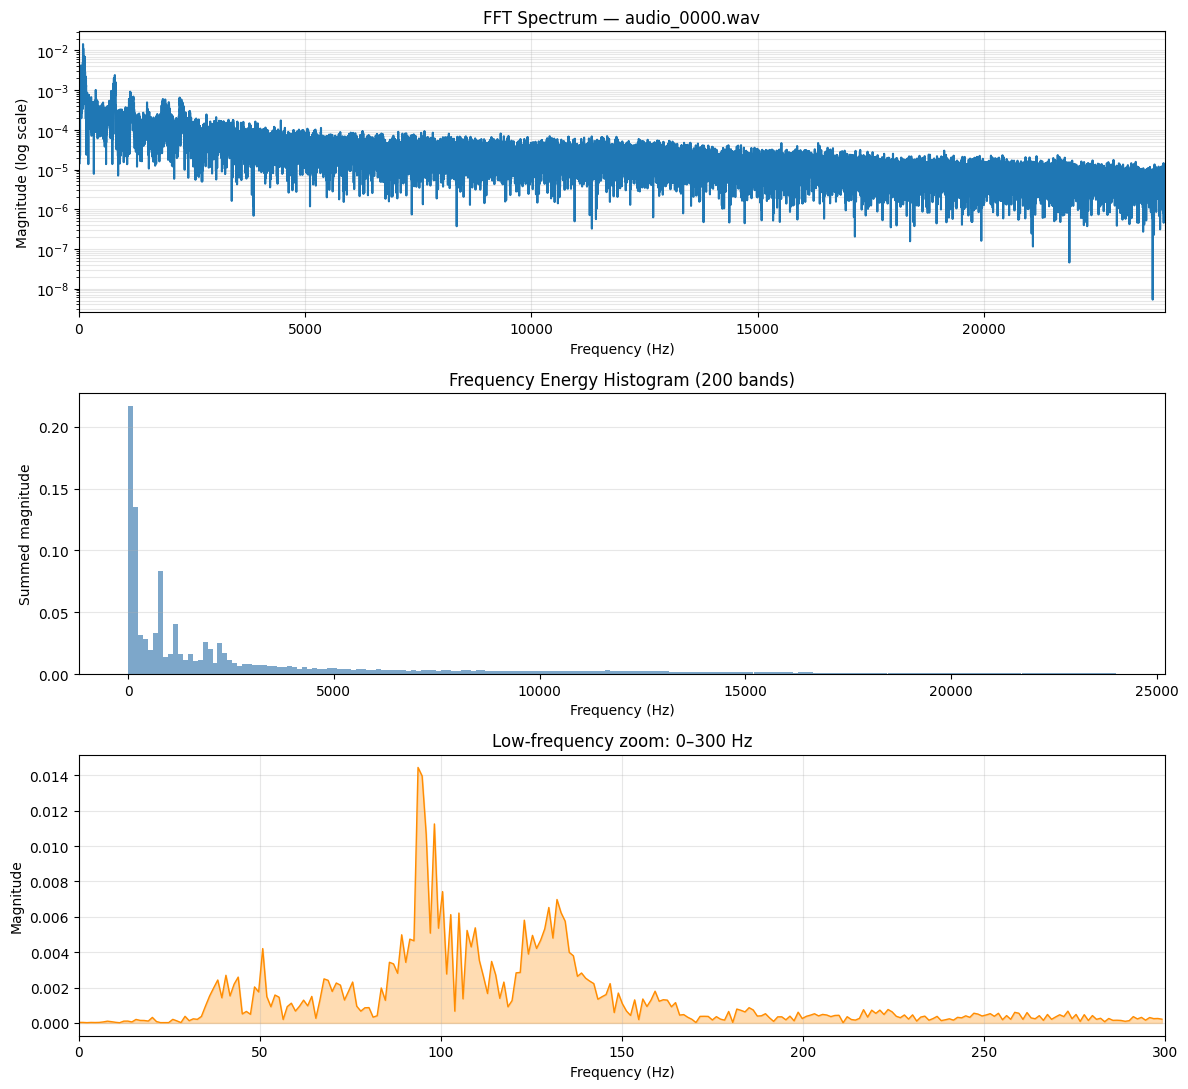

In [2]:
SAMPLE_IDX = 0  # change to inspect a different file

sr, data = wav.read(audio_files[SAMPLE_IDX])
if data.ndim == 2:
    data = data.mean(axis=1)

# Normalize to float [-1, 1]
data = data.astype(np.float32) / np.iinfo(np.int16).max

N = len(data)
freqs = np.fft.rfftfreq(N, d=1.0 / sr)          # frequency axis (Hz)
magnitude = np.abs(np.fft.rfft(data)) / N        # single-sided magnitude

fig, axes = plt.subplots(3, 1, figsize=(12, 11))

# Full spectrum (log scale)
axes[0].semilogy(freqs, magnitude + 1e-10)
axes[0].set_xlabel("Frequency (Hz)")
axes[0].set_ylabel("Magnitude (log scale)")
axes[0].set_title(f"FFT Spectrum — {audio_files[SAMPLE_IDX].name}")
axes[0].set_xlim(0, sr / 2)
axes[0].grid(True, which="both", alpha=0.3)

# Histogram: bin energy into 200 frequency bands
bin_edges = np.linspace(0, sr / 2, 200)
band_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])
band_energy = np.array([
    magnitude[(freqs >= lo) & (freqs < hi)].sum()
    for lo, hi in zip(bin_edges[:-1], bin_edges[1:])
])
axes[1].bar(band_centers, band_energy, width=(sr / 2) / 200,
            color="steelblue", alpha=0.7)
axes[1].set_xlabel("Frequency (Hz)")
axes[1].set_ylabel("Summed magnitude")
axes[1].set_title("Frequency Energy Histogram (200 bands)")
axes[1].grid(True, axis="y", alpha=0.3)

# Zoom: 0–300 Hz (low-frequency detail)
mask_low = freqs <= 300
axes[2].plot(freqs[mask_low], magnitude[mask_low], color="darkorange", lw=1)
axes[2].fill_between(freqs[mask_low], magnitude[mask_low], alpha=0.3, color="darkorange")
axes[2].set_xlabel("Frequency (Hz)")
axes[2].set_ylabel("Magnitude")
axes[2].set_title("Low-frequency zoom: 0–300 Hz")
axes[2].set_xlim(0, 300)
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Cell 2 — Aggregate Frequency Profile Across All Files

**Strategy: average Power Spectral Densities (Welch's method), not raw concatenation.**

Concatenation would distort the spectrum because:
- files have different lengths (unequal weighting)
- boundary discontinuities inject broadband energy

Instead we estimate the PSD of each file independently with Welch's method
(overlapping windows → variance reduction), then average across files.
This gives the *typical* frequency profile of the dataset, plus a ±1 std band
to show variability between recordings.

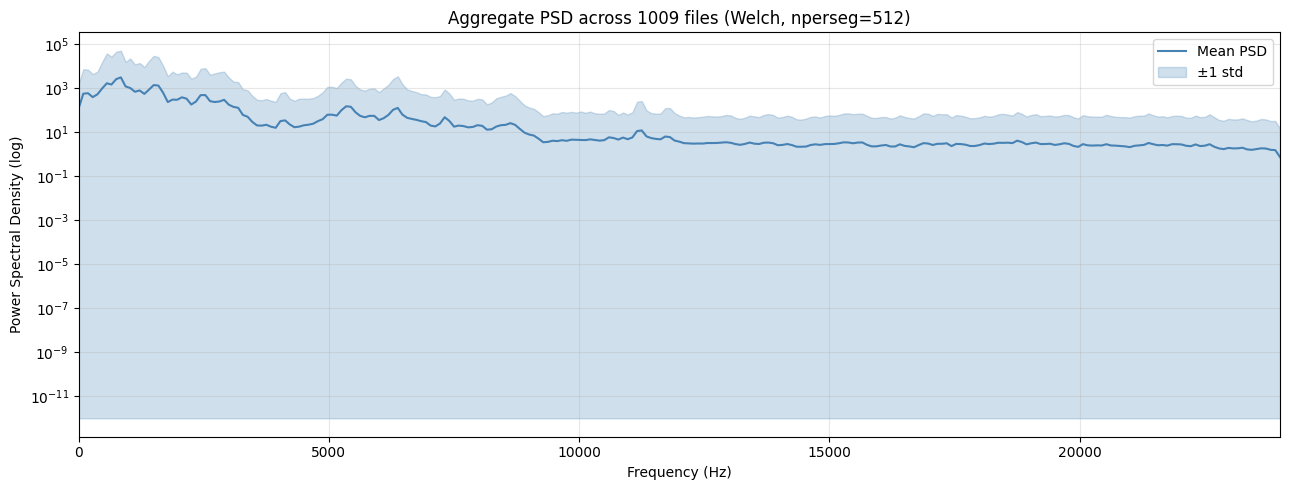

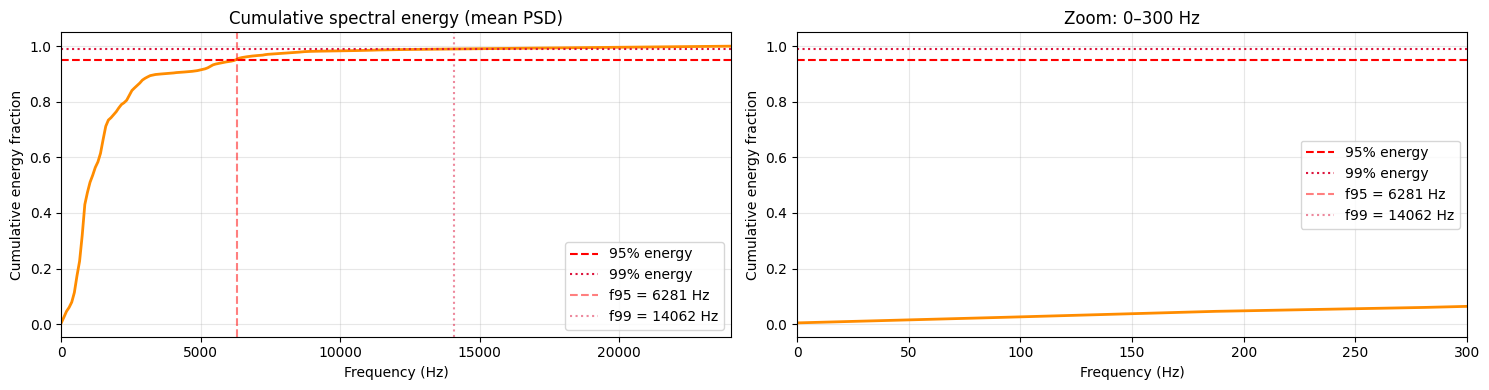

95% of spectral energy is below 6281 Hz
99% of spectral energy is below 14062 Hz


In [3]:
from scipy.signal import welch

NPERSEG = 512   # FFT window length

psds = []
for fpath in audio_files:
    sr_i, d = wav.read(fpath)
    if d.ndim == 2:
        d = d.mean(axis=1)
    d = d.astype(np.float32) / np.iinfo(np.int16).max
    nperseg = min(NPERSEG, len(d))
    f, pxx = welch(d, fs=sr_i, nperseg=nperseg, noverlap=nperseg // 2)
    psds.append(pxx)

# Pad shorter spectra to common length
max_len = max(len(p) for p in psds)
psds_arr = np.array([
    np.pad(p, (0, max_len - len(p)), constant_values=np.nan) for p in psds
])  # shape (n_files, n_freqs)

mean_psd = np.nanmean(psds_arr, axis=0)
std_psd  = np.nanstd(psds_arr,  axis=0)
freq_axis = f  # same for all files (uniform sr)

# Mean PSD with variability band
fig, ax = plt.subplots(figsize=(13, 5))
ax.semilogy(freq_axis, mean_psd, color="steelblue", lw=1.5, label="Mean PSD")
ax.fill_between(freq_axis,
                np.maximum(mean_psd - std_psd, 1e-12),
                mean_psd + std_psd,
                alpha=0.25, color="steelblue", label="±1 std")
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("Power Spectral Density (log)")
ax.set_title(f"Aggregate PSD across {len(audio_files)} files (Welch, nperseg={NPERSEG})")
ax.set_xlim(0, sr_i / 2)
ax.legend()
ax.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.show()

# Cumulative energy — tells you where to put your filter cutoffs
cumulative_energy = np.cumsum(mean_psd) / mean_psd.sum()
f95 = freq_axis[np.searchsorted(cumulative_energy, 0.95)]
f99 = freq_axis[np.searchsorted(cumulative_energy, 0.99)]

fig2, axes2 = plt.subplots(1, 2, figsize=(15, 4))

for ax2, xlim, title in zip(
    axes2,
    [sr_i / 2, 300],
    ["Cumulative spectral energy (mean PSD)", "Zoom: 0–300 Hz"],
):
    ax2.plot(freq_axis, cumulative_energy, color="darkorange", lw=2)
    ax2.axhline(0.95, color="red",    ls="--", label="95% energy")
    ax2.axhline(0.99, color="crimson", ls=":",  label="99% energy")
    ax2.axvline(f95, color="red",    ls="--", alpha=0.5, label=f"f95 = {f95:.0f} Hz")
    ax2.axvline(f99, color="crimson", ls=":",  alpha=0.5, label=f"f99 = {f99:.0f} Hz")
    ax2.set_xlabel("Frequency (Hz)")
    ax2.set_ylabel("Cumulative energy fraction")
    ax2.set_title(title)
    ax2.set_xlim(0, xlim)
    ax2.legend()
    ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"95% of spectral energy is below {f95:.0f} Hz")
print(f"99% of spectral energy is below {f99:.0f} Hz")

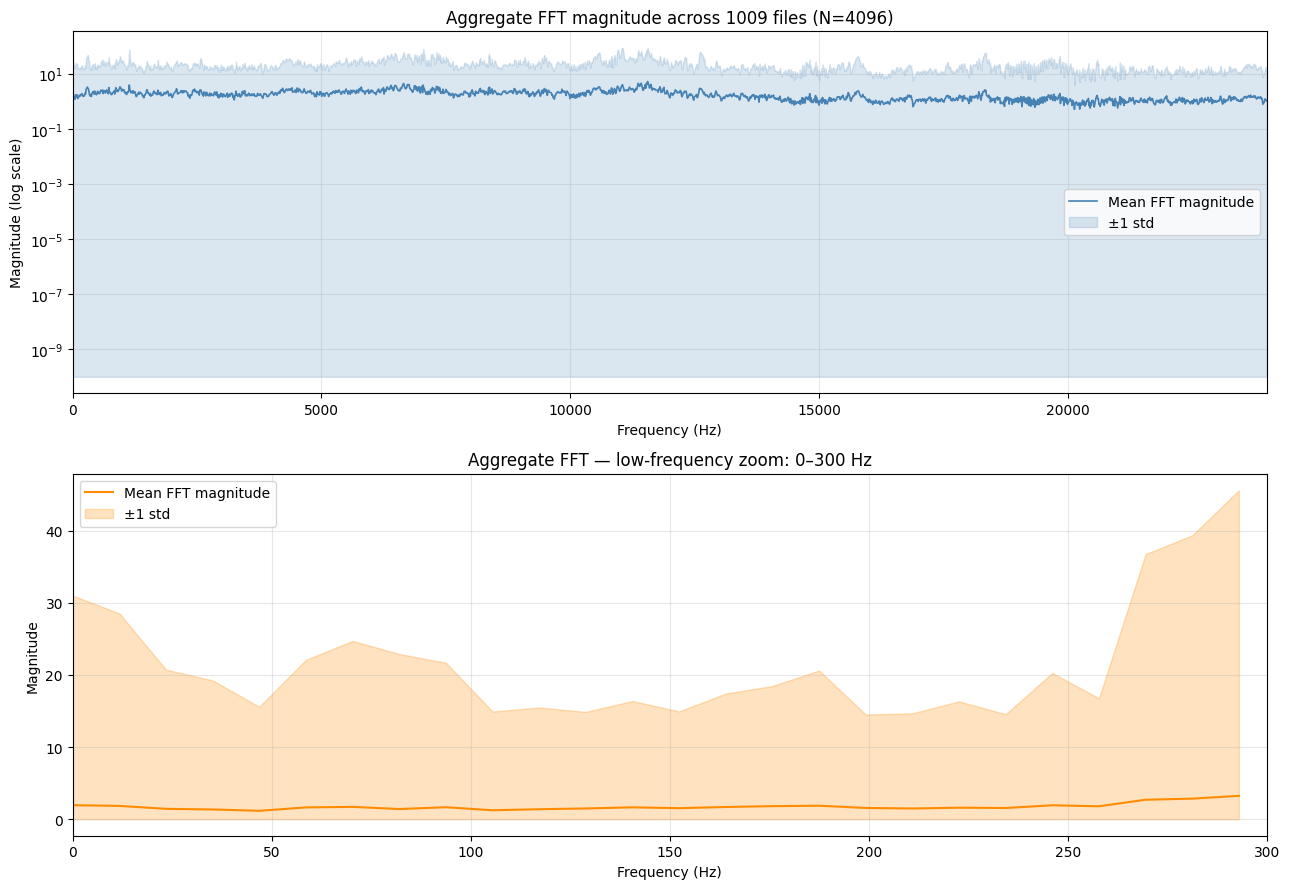

In [4]:
# Aggregate FFT: mean magnitude spectrum across all files
# Each file's FFT is interpolated onto a common frequency grid before averaging,
# so files of different lengths contribute equally.

TARGET_N = 4096  # common FFT length (zero-pad shorter files)

fft_mags = []
for fpath in audio_files:
    sr_i, d = wav.read(fpath)
    if d.ndim == 2:
        d = d.mean(axis=1)
    d = d.astype(np.float32) / np.iinfo(np.int16).max
    # Zero-pad to TARGET_N so all FFTs share the same frequency grid
    n = max(TARGET_N, len(d))
    mag = np.abs(np.fft.rfft(d, n=n)) / len(d)
    fft_mags.append(mag[:TARGET_N // 2 + 1])

fft_arr  = np.array(fft_mags)          # (n_files, n_freqs)
fft_mean = fft_arr.mean(axis=0)
fft_std  = fft_arr.std(axis=0)
fft_freqs = np.fft.rfftfreq(TARGET_N, d=1.0 / sr_i)

fig, axes = plt.subplots(2, 1, figsize=(13, 9))

# Full aggregate FFT (log scale)
axes[0].semilogy(fft_freqs, fft_mean + 1e-10, color="steelblue", lw=1.2, label="Mean FFT magnitude")
axes[0].fill_between(fft_freqs,
                     np.maximum(fft_mean - fft_std, 1e-10),
                     fft_mean + fft_std,
                     alpha=0.2, color="steelblue", label="±1 std")
axes[0].set_xlabel("Frequency (Hz)")
axes[0].set_ylabel("Magnitude (log scale)")
axes[0].set_title(f"Aggregate FFT magnitude across {len(audio_files)} files (N={TARGET_N})")
axes[0].set_xlim(0, sr_i / 2)
axes[0].legend()
axes[0].grid(True, which="both", alpha=0.3)

# Zoom: 0–300 Hz
mask = fft_freqs <= 300
axes[1].plot(fft_freqs[mask], fft_mean[mask], color="darkorange", lw=1.5, label="Mean FFT magnitude")
axes[1].fill_between(fft_freqs[mask],
                     np.maximum(fft_mean[mask] - fft_std[mask], 0),
                     fft_mean[mask] + fft_std[mask],
                     alpha=0.25, color="darkorange", label="±1 std")
axes[1].set_xlabel("Frequency (Hz)")
axes[1].set_ylabel("Magnitude")
axes[1].set_title("Aggregate FFT — low-frequency zoom: 0–300 Hz")
axes[1].set_xlim(0, 300)
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Cell 3 — Filter Design & Denoising

Set `HP_CUTOFF` and `LP_CUTOFF` based on the cumulative energy plot above.
- **High-pass**: removes low-frequency rumble / DC offset (typically < 80 Hz for speech)
- **Low-pass**: removes high-frequency hiss / aliasing artifacts

Both use a Butterworth filter (zero-phase via `sosfiltfilt`).

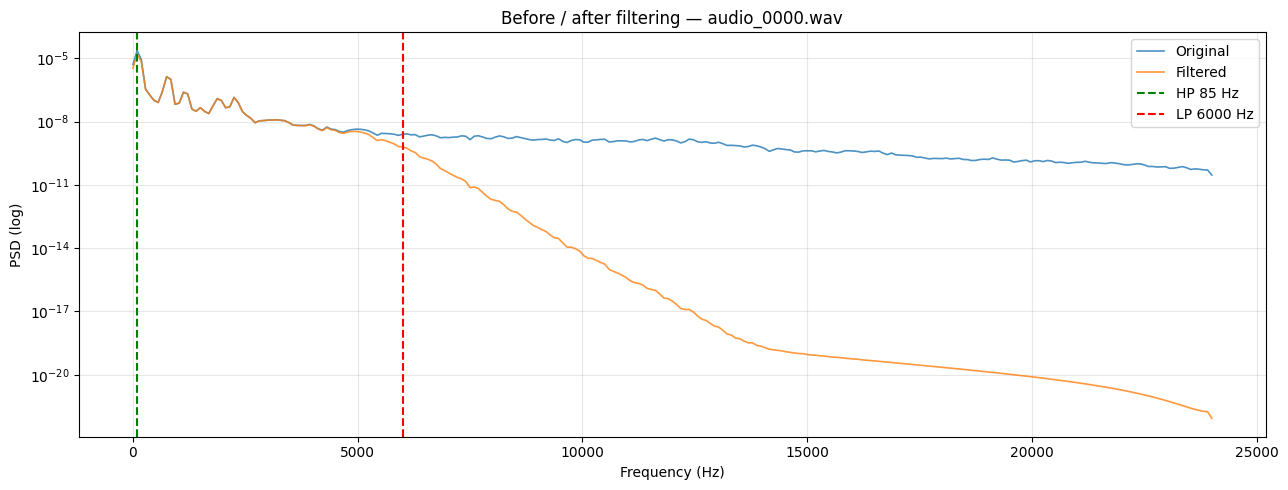

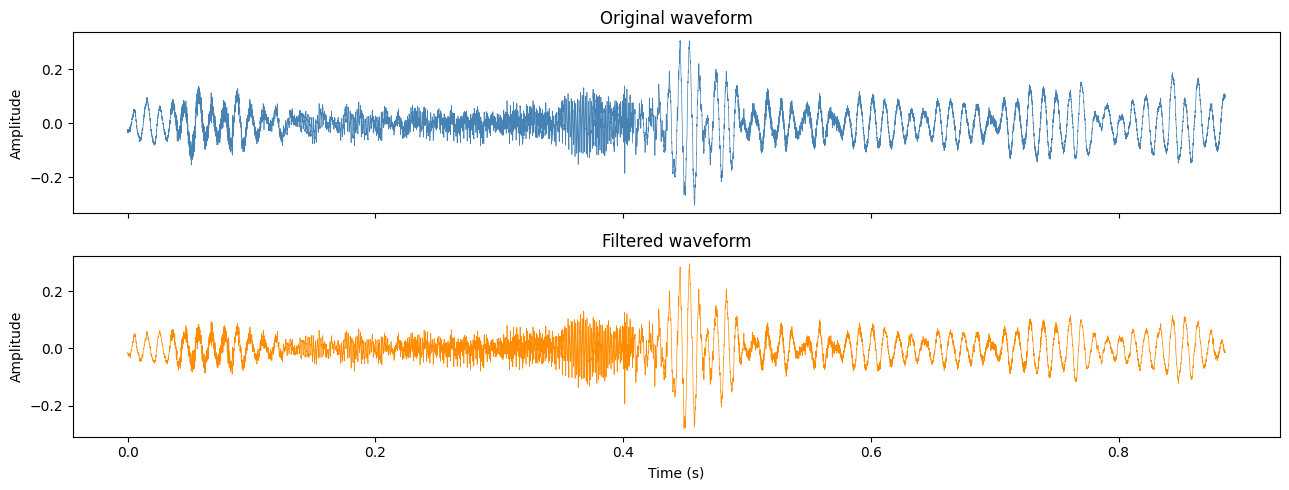

In [13]:
from scipy.signal import butter, sosfiltfilt

# Tune these after inspecting the cumulative energy plot above
HP_CUTOFF    =   85   # Hz — remove everything below this
LP_CUTOFF    = 6000   # Hz — remove everything above this
FILTER_ORDER =    5
PREVIEW_IDX  =    0   # file to preview

def apply_filters(data_f32, fs, hp_hz, lp_hz, order=5):
    nyq = fs / 2
    sos_hp = butter(order, hp_hz / nyq, btype="high", output="sos")
    sos_lp = butter(order, lp_hz / nyq, btype="low",  output="sos")
    out = sosfiltfilt(sos_hp, data_f32)
    out = sosfiltfilt(sos_lp, out)
    return out

def psd_of(sig, fs):
    f, p = welch(sig, fs=fs, nperseg=min(512, len(sig)), noverlap=256)
    return f, p

sr_p, raw_p = wav.read(audio_files[PREVIEW_IDX])
if raw_p.ndim == 2:
    raw_p = raw_p.mean(axis=1)
raw_f  = raw_p.astype(np.float32) / np.iinfo(np.int16).max
filt_f = apply_filters(raw_f, sr_p, HP_CUTOFF, LP_CUTOFF, FILTER_ORDER)

f_raw,  p_raw  = psd_of(raw_f,  sr_p)
f_filt, p_filt = psd_of(filt_f, sr_p)

# PSD before/after
fig, ax = plt.subplots(figsize=(13, 5))
ax.semilogy(f_raw,  p_raw,  label="Original", alpha=0.8, lw=1.2)
ax.semilogy(f_filt, p_filt, label="Filtered",  alpha=0.8, lw=1.2)
ax.axvline(HP_CUTOFF, color="green", ls="--", label=f"HP {HP_CUTOFF} Hz")
ax.axvline(LP_CUTOFF, color="red",   ls="--", label=f"LP {LP_CUTOFF} Hz")
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("PSD (log)")
ax.set_title(f"Before / after filtering — {audio_files[PREVIEW_IDX].name}")
ax.legend()
ax.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.show()

# Waveform before/after
t = np.arange(len(raw_f)) / sr_p
fig2, axes2 = plt.subplots(2, 1, figsize=(13, 5), sharex=True)
axes2[0].plot(t, raw_f,  lw=0.5, color="steelblue")
axes2[0].set_ylabel("Amplitude")
axes2[0].set_title("Original waveform")
axes2[1].plot(t, filt_f, lw=0.5, color="darkorange")
axes2[1].set_ylabel("Amplitude")
axes2[1].set_title("Filtered waveform")
axes2[1].set_xlabel("Time (s)")
plt.tight_layout()
plt.show()

## Cell 4 — Export All Denoised Files

Applies the band-pass filter to every file and saves to `denoised_audios/` as 16-bit mono WAV.

In [14]:
OUT_DIR = Path("denoised_audios")
OUT_DIR.mkdir(exist_ok=True)

for fpath in audio_files:
    sr_i, d = wav.read(fpath)
    if d.ndim == 2:
        d = d.mean(axis=1)
    d_f = d.astype(np.float32) / np.iinfo(np.int16).max
    d_clean = apply_filters(d_f, sr_i, HP_CUTOFF, LP_CUTOFF, FILTER_ORDER)
    d_clean = np.clip(d_clean, -1.0, 1.0)
    d_int16 = (d_clean * np.iinfo(np.int16).max).astype(np.int16)
    wav.write(OUT_DIR / fpath.name, sr_i, d_int16)

print(f"Saved {len(audio_files)} denoised files to '{OUT_DIR}/'")
print(f"  High-pass cutoff : {HP_CUTOFF} Hz")
print(f"  Low-pass cutoff  : {LP_CUTOFF} Hz")
print(f"  Filter order     : {FILTER_ORDER} (Butterworth, zero-phase)")

Saved 1009 denoised files to 'denoised_audios/'
  High-pass cutoff : 85 Hz
  Low-pass cutoff  : 6000 Hz
  Filter order     : 5 (Butterworth, zero-phase)
